# 01 — Setup Check & xBD Dataset Verification

**Project:** Building Damage Assessment from Pre/Post-Disaster Satellite Imagery
**Phase:** 0 — Setup and Data Acquisition
**Dataset:** [`qianlanzz/xbd-dataset`](https://www.kaggle.com/datasets/qianlanzz/xbd-dataset) (Kaggle)

### Goal
Verify that the xBD dataset available on Kaggle is complete and usable for this project:
1. Check which splits exist and whether each split has images, labels and masks.
2. Find out what the `train/` folder contains.
3. Inspect the pre-made masks to understand their format.

## 1. Setup

In [19]:
%cd /kaggle/working
!rm -rf damage-detection
!git clone -b phase-0-setup https://github.com/azrairemd/damage-detection.git
%cd damage-detection
!pip install -q -r requirements.txt
!pip install -q -e .
!pip show damage-detection

/kaggle/working
Cloning into 'damage-detection'...
remote: Enumerating objects: 41, done.
remote: Counting objects: 100% (41/41), done.
remote: Compressing objects: 100% (31/31), done.
remote: Total 41 (delta 8), reused 34 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (41/41), 21.37 KiB | 911.00 KiB/s, done.
Resolving deltas: 100% (8/8), done.
/kaggle/working/damage-detection
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for damage-detection (pyproject.toml) ... done
Name: damage-detection
Version: 0.0.1
Summary: Building damage assessment from pre/post-disaster satellite imagery (xBD) with a Siamese U-Net and Grad-CAM.
Home-page: 
Author: Azra İrem Dalhasanoğlu
Author-email: 
License: 
Location: /usr/local/lib/python3.13/dist-packages
Editable project location: /kaggle/working/damage-detection


## 2. Data verification

In [20]:
import os
import glob
import numpy as np
from PIL import Image

In [21]:
ROOT = "/kaggle/input/datasets/qianlanzz/xbd-dataset/xbd"   

In [22]:
for split in sorted(os.listdir(ROOT)):
    for sub in ["images", "labels", "masks"]:
        path = os.path.join(ROOT, split, sub)
        if os.path.isdir(path):
            print(f"{split:6s} {sub:7s} {len(os.listdir(path)):6d}")

hold   images    1866
hold   labels    1866
hold   masks     2799
test   images    1866
test   labels    1866
test   masks     2799
tier1  images    5598
tier1  labels    5598
tier1  masks     8397
tier3  images   12738
tier3  labels   12738
tier3  masks    19107
train  images      10


In [23]:
train_imgs = set(os.listdir(os.path.join(ROOT, "train", "images")))
tier1_imgs = set(os.listdir(os.path.join(ROOT, "tier1", "images")))
tier3_imgs = set(os.listdir(os.path.join(ROOT, "tier3", "images")))

print("train          :", len(train_imgs))
print("train ∩ tier1  :", len(train_imgs & tier1_imgs))
print("train ∩ tier3  :", len(train_imgs & tier3_imgs))
print("train only     :", len(train_imgs - tier1_imgs - tier3_imgs))

train          : 10
train ∩ tier1  : 10
train ∩ tier3  : 0
train only     : 0


In [24]:
first_img = sorted(os.listdir(os.path.join(ROOT, "tier1", "images")))[0]
sample_id = first_img.replace("_pre_disaster.png", "").replace("_post_disaster.png", "")
print("sample_id:", sample_id)

pattern = os.path.join(ROOT, "tier1", "masks", sample_id + "*")
for path in sorted(glob.glob(pattern)):
    mask = np.array(Image.open(path))
    print(os.path.basename(path), mask.shape, mask.dtype, np.unique(mask))

sample_id: guatemala-volcano_00000000
guatemala-volcano_00000000_post_disaster.png (1024, 1024) uint8 [0 1]
guatemala-volcano_00000000_post_disaster_rgb.png (1024, 1024, 3) uint8 [  0 255]
guatemala-volcano_00000000_pre_disaster.png (1024, 1024) uint8 [  0 255]


## 3. Loading a pair with the src package

tier1   2799 pairs
tier3   6369 pairs
test     933 pairs
hold     933 pairs
guatemala-volcano_00000000 (1024, 1024, 3) uint8 (1024, 1024, 3) uint8


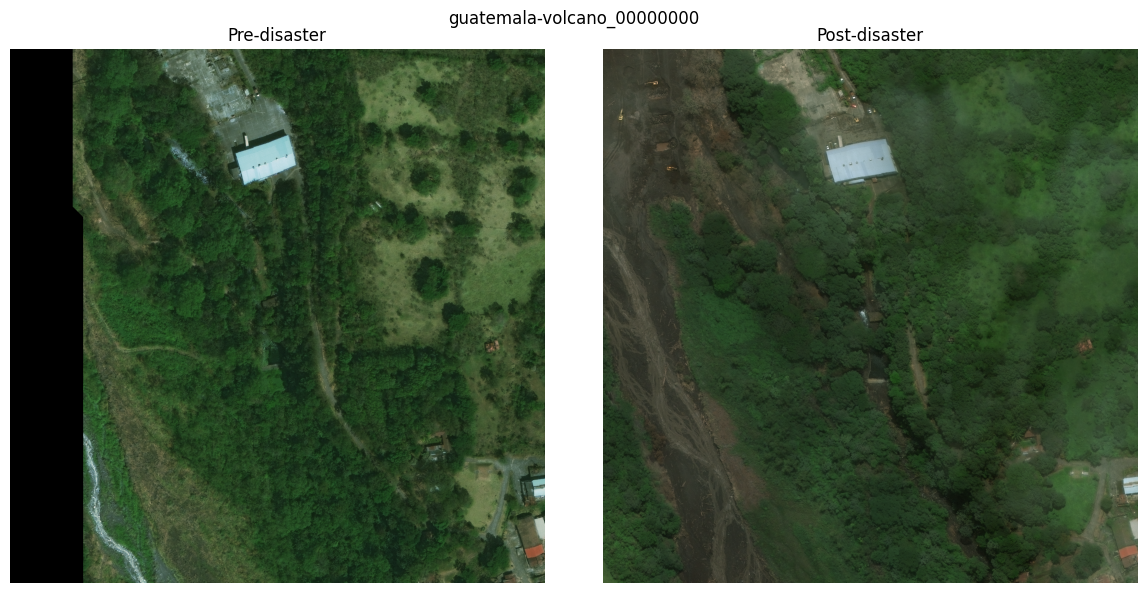

In [25]:
import matplotlib.pyplot as plt

from src.data.xbd import SPLITS, list_image_ids, load_pair

for folder in SPLITS:
    print(f"{folder:6s} {len(list_image_ids(ROOT, folder)):5d} pairs")

image_id = list_image_ids(ROOT, "tier1")[0]
pre, post = load_pair(ROOT, "tier1", image_id)
print(image_id, pre.shape, pre.dtype, post.shape, post.dtype)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(pre)
axes[0].set_title("Pre-disaster")
axes[1].imshow(post)
axes[1].set_title("Post-disaster")
for ax in axes:
    ax.axis("off")
fig.suptitle(image_id)
plt.tight_layout()
plt.show()

## Findings

### 0. Setup check ✅
- The repository was cloned from GitHub, installed with `pip install -e .`, and `src.data.xbd` was imported successfully.
- `list_image_ids` returns the same pair counts as the manual check (2,799 / 6,369 / 933 / 933).
- `load_pair` returns two RGB arrays of shape `(1024, 1024, 3)`, dtype `uint8`.
- Observation: some images contain **no-data regions** (black areas, e.g. left edge of the pre-disaster image above). To be analyzed in Phase 2 (EDA).
  
### 1. Dataset structure
| Split | Images | Pairs | Labels | Masks |
|---|---|---|---|---|
| tier1 | 5,598 | 2,799 | ✅ | ✅ |
| tier3 | 12,738 | 6,369 | ✅ | ✅ |
| test | 1,866 | 933 | ✅ | ✅ |
| hold | 1,866 | 933 | ✅ | ✅ |
| **Total** | **22,068** | **11,034** | | |

- The total of **22,068 images** matches the official xBD release → the dataset is **complete**.
- Every split has the same number of images and label files → **no missing labels**.
- `tier1` corresponds to the official xBD **train** split.

### 2. The `train/` folder
- Contains only **10 images**, all of which also exist in `tier1`, and has no labels.
- It is a sample folder left by the uploader → **ignored** in this project.

### 3. Pre-made masks
Each pair has 3 mask files:

| File | Shape | Values | Meaning |
|---|---|---|---|
| `*_pre_disaster.png` | (1024, 1024) | {0, 255} | Binary building localization mask |
| `*_post_disaster.png` | (1024, 1024) | class ids | Damage mask (one class id per pixel) |
| `*_post_disaster_rgb.png` | (1024, 1024, 3) | {0, 255} | Color visualization only, not used for training |

## Decisions
- **Data pool:** `tier1 + tier3 + test + hold` → **11,034 pairs**.
- **Split:** Our own 60/20/20 stratified split (by disaster event) → approx. **6,620 / 2,207 / 2,207** pairs.
- **Masks:** We will generate our own masks from the JSON polygons in Phase 3, so that we fully control the class encoding. The pre-made masks will be used as a cross-check.
- **Note for the report:** Since the official test/hold sets are pooled into our own split, our test scores are **not directly comparable** to the xView2 leaderboard.